# ABC Bank drift model: SHAP analysis notebook (Module 4)

Explains the champion model trained by `python -m src.model.run_all`:
global importance (SHAP), local explanations (SHAP and LIME) for three customers, and counterfactuals.

Run from the repository root after training:
`jupyter nbconvert --to notebook --execute --inplace notebooks/04_shap_analysis.ipynb`

The cells marked **Your interpretation** are for the analyst's own reading of the results.

In [1]:
import json, os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import joblib, pandas as pd, matplotlib.pyplot as plt, shap
from src.model import explain
from src.model.dataset import build_modelling_table, load_inputs, split
%matplotlib inline

meta = json.loads(Path("models/model_meta.json").read_text())
model = joblib.load("models/drift_model.joblib")
monthly, audit_table = load_inputs()
X, y, s, report = build_modelling_table(monthly, audit_table, meta.get("target_rule", "inactive_or_dropping"))
X_tr, X_te, y_tr, y_te, s_tr, s_te = split(X, y, s)
threshold = meta["threshold"]
scores = model.predict_proba(X_te)[:, 1]
print(f"Champion: {meta['champion']} | test customers: {len(X_te):,} | drift rate: {y_te.mean():.3f} | threshold: {threshold:.3f}")

C:\Users\Rhienney\OneDrive\Desktop\abc-bank-segmentation\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Champion: random_forest | test customers: 4,168 | drift rate: 0.086 | threshold: 0.465


## 1. Global feature importance (SHAP)

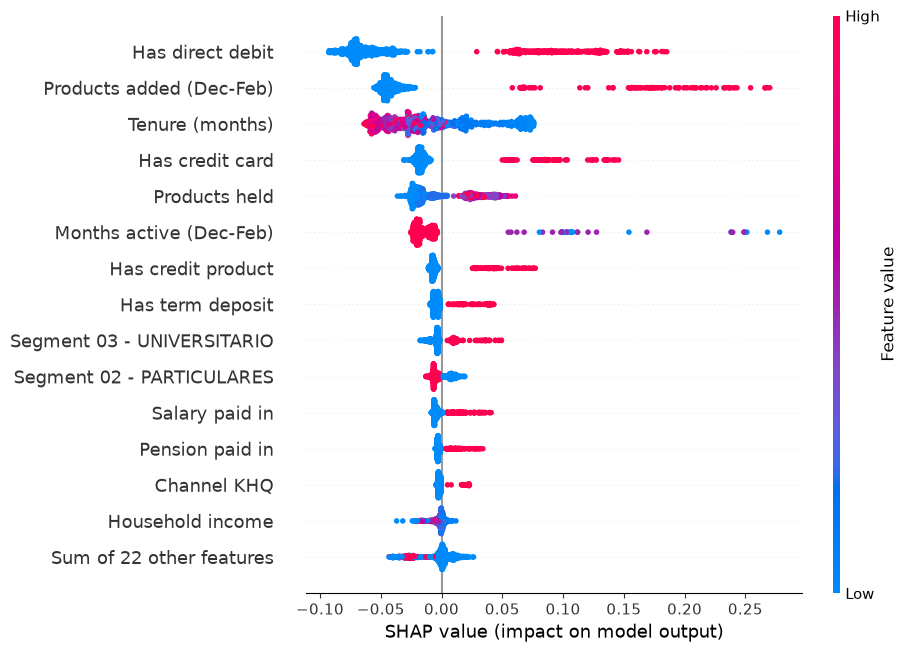

In [2]:
sample = X_te.sample(1000, random_state=42).index
examples = explain.pick_examples(y_te, scores, threshold)
rows = sorted(set(sample) | set(examples.values()))
X_exp = X_te.loc[rows].reset_index(drop=True)
pos = {k: rows.index(v) for k, v in examples.items()}
exp = explain.shap_explanation(model, X_tr.sample(300, random_state=42), X_exp)
shap.plots.beeswarm(exp, max_display=15)

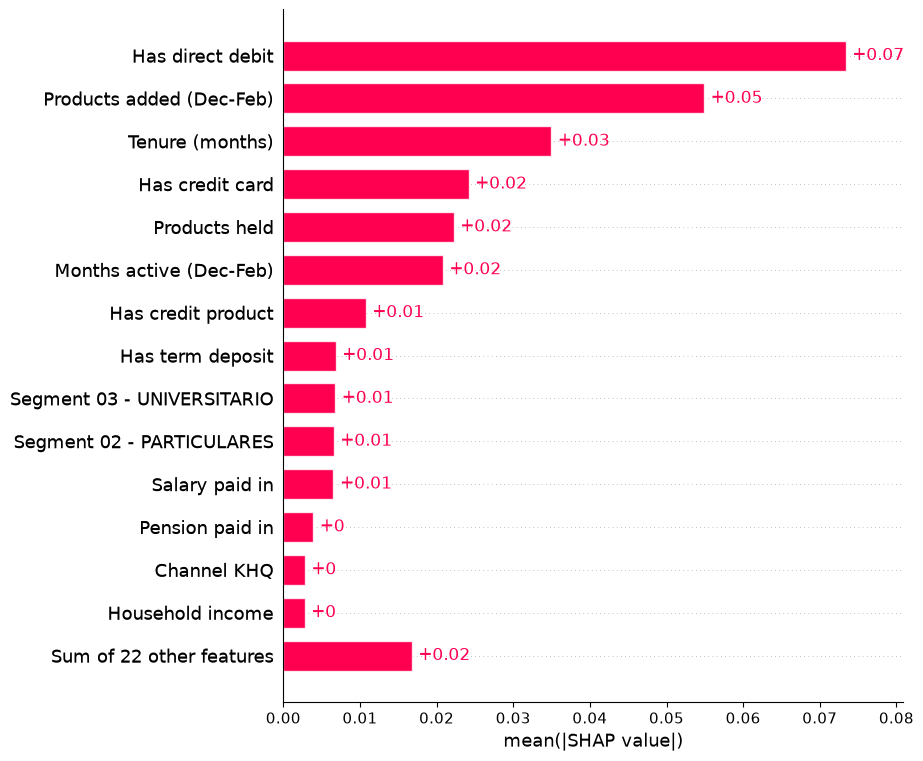

,feature,mean_abs_shap,mean_shap
15,Has direct debit,0.0734,-0.0192
1,Products added (Dec-Feb),0.0549,-0.0223
5,Tenure (months),0.0350,-0.0087
13,Has credit card,0.0242,-0.0072
0,Products held,0.0222,-0.0025
3,Months active (Dec-Feb),0.0208,-0.0100
12,Has credit product,0.0107,-0.0015
10,Has term deposit,0.0068,-0.0010
31,Segment 03 - UNIVERSITARIO,0.0068,-0.0005
30,Segment 02 - PARTICULARES,0.0066,-0.0011


In [3]:
shap.plots.bar(exp, max_display=15)
importance = pd.DataFrame({"feature": exp.feature_names, "mean_abs_shap": abs(exp.values).mean(0),
                           "mean_shap": exp.values.mean(0)}).sort_values("mean_abs_shap", ascending=False)
importance.head(10).round(4)

**Your interpretation:** what do the top three features mean for ABC Bank's relationship managers?
Do any of them surprise you, or look like they reflect how the target was defined rather than real behaviour?

## 2. How the top feature changes risk (SHAP dependence)

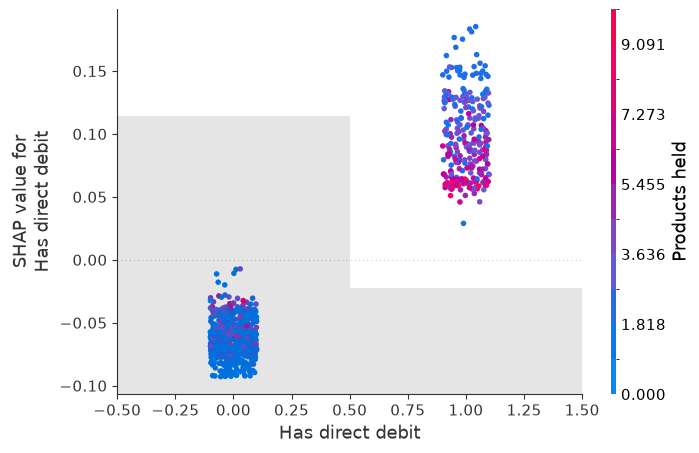

In [4]:
top_feature = importance.iloc[0]["feature"]
shap.plots.scatter(exp[:, top_feature], color=exp)

## 3. Local explanations for three customers (SHAP)

In [5]:
pd.DataFrame([{"case": k, "risk": round(float(scores[v]), 3), "actual_drift": int(y_te[v])} for k, v in examples.items()])

,case,risk,actual_drift
0,High risk (correctly flagged),0.872,1
1,Borderline,0.465,0
2,Low risk,0.192,0


In [ ]:
for label, i in pos.items():
    print(label)
    shap.plots.waterfall(exp[i], max_display=10)

## 4. LIME for the same customers (does it agree with SHAP?)

In [7]:
lime_table = explain.lime_local(model, X_tr, X_exp, pos, Path("reports/model"))
lime_table[lime_table["rank"] <= 5]

,case,rank,rule,weight,effect
0,High risk (correctly flagged),1,Products added (Dec-Feb) > 0.00,0.2347,raises risk
1,High risk (correctly flagged),2,0.00 < Has direct debit <= 1.00,0.1475,raises risk
2,High risk (correctly flagged),3,Has credit card > 0.00,0.1151,raises risk
3,High risk (correctly flagged),4,Tenure (months) > 152.00,-0.0552,lowers risk
4,High risk (correctly flagged),5,Has credit product > 0.00,0.0525,raises risk
8,Borderline,1,Products added (Dec-Feb) <= 0.00,-0.2369,lowers risk
9,Borderline,2,0.00 < Has direct debit <= 1.00,0.1467,raises risk
10,Borderline,3,Has credit card <= 0.00,-0.1097,lowers risk
11,Borderline,4,Tenure (months) > 152.00,-0.0462,lowers risk
12,Borderline,5,Has credit product <= 0.00,-0.0374,lowers risk


**Your interpretation:** for each customer, do SHAP and LIME point to the same drivers?
Write one plain-English sentence a relationship manager could use with that customer.

## 5. Counterfactuals: what would change the outcome?

In [8]:
explain.offer_effects(model, X_te, threshold)

,offer,flagged_customers_eligible,mean_change_in_risk,share_moved_below_threshold
0,Open an e-account (digital banking),1170,0.1496,0.0
1,Set up a direct debit,489,0.1669,0.0
2,Take up a card,1204,0.1975,0.0
3,Move salary to ABC Bank,991,0.1499,0.0


In [9]:
explain.counterfactuals(model, X_te, threshold).head(10)

,row,risk_before,change_needed,risk_after,offers_needed
0,555,0.466,No realistic offer set found,None,None
1,3744,0.466,No realistic offer set found,None,None
2,1187,0.467,No realistic offer set found,None,None
3,2686,0.467,No realistic offer set found,None,None
4,1395,0.467,No realistic offer set found,None,None
5,2408,0.467,No realistic offer set found,None,None
6,2068,0.467,No realistic offer set found,None,None
7,4017,0.467,No realistic offer set found,None,None
8,1970,0.467,No realistic offer set found,None,None
9,3491,0.467,No realistic offer set found,None,None


**Your interpretation:** which offers lower predicted drift risk, and which raise it? What does that say about
the target definition and about which offers ABC Bank should test first (with a control group)?